# 06 - OLS baseline: the control in my completed experiment

**Learning goal:** trace the unchanged features and target through splitting,
fold-local preprocessing, least squares, and the actual saved OLS results.
This notebook reads completed artifacts; it does not train, tune, or predict
on the test set. The saved Ridge model remains selected.

**Evidence boundary:** the experiment saved OLS scores but not the fitted OLS
pipeline, coefficients, fold predictions, or per-customer residuals.
We can explain the mathematics and recorded performance, but cannot invent
a coefficient table or residual distribution. The later notebooks maintain
the same distinction. Install the package and artifact runtime described in
[the README](../README.md), then select that Python kernel.

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, train_test_split
from ecommerce_customer_value_prediction.models.predict import load_model

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "reports" / "metrics" / "final_experiment").is_dir(), "Run from repo root or notebooks/"
EXPERIMENT = ROOT / "reports" / "metrics" / "final_experiment"

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

protected = [
    path for directory in (EXPERIMENT, ROOT / "models")
    for path in directory.rglob("*") if path.is_file()
]
initial_hashes = {str(path): sha256(path) for path in protected}

# This is an artifact-reading lesson, not another modeling experiment.
def forbid_fit(*args, **kwargs):
    raise RuntimeError("Fitting/tuning is forbidden in this completed-experiment lesson.")

for cls in (Pipeline, LinearRegression, Ridge, Lasso, ElasticNet,
            StandardScaler, OneHotEncoder, GridSearchCV, RandomizedSearchCV):
    cls.fit = forbid_fit

def read_json(name):
    return json.loads((EXPERIMENT / name).read_text(encoding="utf-8"))

lock = read_json("selection.json")
test_report = read_json("test_metrics.json")
errors = read_json("error_analysis.json")
metadata = json.loads((ROOT / "models" / "model_metadata.json").read_text(encoding="utf-8"))
cv_grid = pd.read_csv(EXPERIMENT / "cv_results.csv")
assert sha256(EXPERIMENT / "selection.json") == test_report["selection_sha256"]
assert metadata["selection_sha256"] == test_report["selection_sha256"]
assert lock["selected_model"] == metadata["model_type"] == errors["model"]
assert metadata["final_test_metrics"] == test_report["models"][lock["selected_model"]]
assert pd.Timestamp(lock["locked_at"]) < pd.Timestamp(test_report["evaluated_at"])
winner = lock["selected_model"]
candidates = lock["candidates"]
cv_summary = pd.DataFrame({
    name: candidate["cv_metrics"] for name, candidate in candidates.items()
}).T
cv_metric_columns = [
    "mean_cv_rmse_log", "std_cv_rmse_log", "mean_cv_mae_log",
    "std_cv_mae_log", "mean_cv_r2_log", "std_cv_r2_log"
]
cv_summary[cv_metric_columns] = cv_summary[cv_metric_columns].astype(float)
test_summary = pd.DataFrame(test_report["models"]).T
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 6)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True})

def cv_curve(model, ax):
    points = cv_grid.loc[cv_grid["model"].eq(model)].sort_values("alpha")
    ax.errorbar(points["alpha"], points["mean_cv_rmse_log"],
                yerr=points["std_cv_rmse_log"], fmt="o-", capsize=3,
                label="Saved CV mean +/- fold SD (not a confidence interval)")
    chosen_alpha = candidates[model]["hyperparameters"]["alpha"]
    ax.axvline(chosen_alpha, color="crimson", linestyle="--", label=f"Locked alpha={chosen_alpha:g}")
    ax.set(xscale="log", xlabel="alpha (log axis)", ylabel="CV RMSE, log1p target",
           title=f"{model}: saved training-only CV evidence")
    ax.legend(fontsize=8)

def ridge_coefficients():
    pipeline = load_model(ROOT / "models" / "customer_value_model.joblib")
    preprocessor = pipeline.named_steps["preprocessor"]
    coefficients = pipeline.named_steps["regressor"].coef_
    table = pd.DataFrame({
        "encoded_feature": preprocessor.get_feature_names_out(),
        "coefficient": coefficients,
        "absolute_coefficient": np.abs(coefficients),
    })
    return pipeline, table

print("Source: completed experiment artifacts; fit/tuning calls are blocked.")
print("Winner:", winner, "| hyperparameters:", candidates[winner]["hyperparameters"])
print("Locked at:", lock["locked_at"], "| evaluated at:", test_report["evaluated_at"])
print("Protected files:", len(protected), "| no test predictions are recomputed.")

2026-10-11 00:38:04.424 | INFO     | ecommerce_customer_value_prediction.config.settings:<module>:33 - PROJ_ROOT: C:\Masters_AIDSE_IIT\AI_Code\ecommerce-customer-value-prediction


Source: completed experiment artifacts; fit/tuning calls are blocked.
Winner: ridge | hyperparameters: {'alpha': 10.0, 'copy_X': True, 'fit_intercept': True, 'max_iter': None, 'positive': False, 'random_state': None, 'solver': 'auto', 'tol': 0.0001}
Locked at: 2026-10-10T18:40:42.345137+00:00 | evaluated at: 2026-10-10T18:40:42.385874+00:00
Protected files: 8 | no test predictions are recomputed.


## 1. What were X and y?

There are eight **input fields**, not necessarily eight encoded columns:
seven numeric features plus country, which expands into country indicators.
`Customer ID` is a key, not a predictor. Neither `future_revenue` nor
`log1p_future_revenue` belongs in X.

Features use transactions **strictly before 2011-09-01**. Gross future revenue
sums cleaned purchase value **on or after that cutoff**. Customers without
historical purchases are excluded; historical customers without future
purchases receive zero revenue.

In [2]:
feature_definitions = {
    "recency_days": "Whole days from last historical purchase to cutoff",
    "frequency": "Distinct historical invoice count",
    "monetary": "Sum of historical line_total in GBP",
    "avg_basket_value": "Mean historical invoice spend in GBP",
    "unique_products": "Distinct historical StockCode count",
    "tenure_days": "Whole days between first and last historical purchases",
    "purchase_rate": "frequency / tenure_days; zero if tenure_days=0",
    "country": "Country of most recent historical transaction",
}
display(pd.DataFrame({
    "feature": lock["features"],
    "type": ["numeric" if f in lock["numeric_features"] else "categorical"
             for f in lock["features"]],
    "definition": [feature_definitions[f] for f in lock["features"]],
}))
display(pd.Series({
    "target": lock["target"],
    "transformation": lock["target_transformation"],
    "cutoff": lock["prediction_cutoff"],
    "observed_end": lock["dataset"]["observation_end"],
    "observed_target_days": lock["dataset"]["observed_target_days"],
    "customers": lock["dataset"]["n_customers"],
    "zero_revenue_fraction": lock["dataset"]["zero_revenue_fraction"],
}, name="Saved problem definition"))

,feature,type,definition
0,recency_days,numeric,Whole days from last historical purchase to cu...
1,frequency,numeric,Distinct historical invoice count
2,monetary,numeric,Sum of historical line_total in GBP
3,avg_basket_value,numeric,Mean historical invoice spend in GBP
4,unique_products,numeric,Distinct historical StockCode count
5,tenure_days,numeric,Whole days between first and last historical p...
6,purchase_rate,numeric,frequency / tenure_days; zero if tenure_days=0
7,country,categorical,Country of most recent historical transaction


target                   log1p_future_revenue
transformation                          log1p
cutoff                             2011-09-01
observed_end              2011-12-09 12:20:00
observed_target_days                       99
customers                                4374
zero_revenue_fraction                0.647005
Name: Saved problem definition, dtype: object

## 2. Why log1p?

For revenue \(r\geq0\), the model target is \(y=\log(1+r)\).
`log1p(0)=0`: zero-revenue customers are valid training observations.
The inverse is \(\widehat r=\exp(\widehat y)-1\), implemented by `expm1`.

A large revenue range becomes a much smaller target range. This changes the
error weighting: squared errors in **log space** are not squared GBP errors.
The transformation does not guarantee normal residuals, calibrated mean
revenue, nonnegative predictions, or accurate tail behavior.
The intended horizon was approximately four months, but the observed extract
ends on December 9 (99 days after cutoff). The code sums all available
post-cutoff rows; it does not enforce a December 31 endpoint.

In [3]:
# Analytic examples, not customer predictions or a new model evaluation.
revenue_examples = np.array([0., 10., 100., 1000., 10000.])
display(pd.DataFrame({
    "illustrative_revenue_gbp": revenue_examples,
    "log1p": np.log1p(revenue_examples),
    "roundtrip_expm1": np.expm1(np.log1p(revenue_examples)),
}))

,illustrative_revenue_gbp,log1p,roundtrip_expm1
0,0.0,0.000000,0.0
1,10.0,2.397895,10.0
2,100.0,4.615121,100.0
3,1000.0,6.908755,1000.0
4,10000.0,9.210440,10000.0


## 3. Split first, cross-validate only the training partition

The source pipeline reserved 20% of customers, stratifying on the binary
label `future_revenue > 0` and using seed 42. Stratification preserves the
zero/positive proportion; that label is never a model feature.

The remaining 80% supplies five shuffled, binary-stratified CV folds.
For each fold, fit preprocessing and the model on four folds, then score
the fifth. Aggregate fold RMSE/MAE/R2 to estimate development performance.
**The reserved test customers never enter tuning or CV.**
This is a customer holdout, not a rolling temporal backtest.

In [4]:
display(pd.Series(lock["split"], name="Actual reserved split"))
display(pd.Series(lock["cv"], name="Actual training-only cross-validation"))

test_size                                                                  0.2
random_state                                                                42
stratification                                              future_revenue > 0
n_train                                                                   3499
n_test                                                                     875
train_customer_ids_sha256    acdacb13fc44741359bf5b7d86b44fa6a52e3d65e02080...
test_customer_ids_sha256     2bcf6835ecfab669e9e7b2dd6b5b72c207a1efb4d4ea60...
Name: Actual reserved split, dtype: object

n_folds                            5
random_state                      42
stratification    future_revenue > 0
Name: Actual training-only cross-validation, dtype: object

## 4. StandardScaler, OneHotEncoder, and Pipeline

For a numeric feature \(x_j\), StandardScaler computes
\(z_j=(x_j-\mu_j)/s_j\) using the training fold's mean and standard deviation.
This puts quantities such as monetary and purchase_rate on comparable scales.
Scaling is especially important for the later coefficient penalties: units
should not decide which coefficient gets penalized most.

OneHotEncoder replaces country with binary indicators. It does not impose a
false numerical ordering on countries. `handle_unknown="ignore"` maps an
unseen country to all-zero country indicators; acceptance is not proof that
predictions generalize geographically.

A ColumnTransformer applies these two paths, and a Pipeline joins that
preprocessing to the estimator. Passing the **whole Pipeline** into CV
refits transformations within each training fold and prevents preprocessing
leakage. Fitting a scaler once on all rows before CV would break this rule.
The shared preprocessing makes OLS a fair control for the penalized models.

In [5]:
display(pd.Series(lock["preprocessing"], name="Saved shared preprocessing"))
display(Markdown("**Data flow:** raw customer features -> fold-fitted scaling / "
                 "country encoding -> OLS -> log1p prediction"))

numeric                                           StandardScaler
categorical    OneHotEncoder(handle_unknown='ignore', sparse_...
remainder                                                   drop
Name: Saved shared preprocessing, dtype: str

**Data flow:** raw customer features -> fold-fitted scaling / country encoding -> OLS -> log1p prediction

## 5. OLS from first principles

On encoded/scaled inputs \(z_{ij}\), the prediction is
\[
  \widehat y_i=\beta_0+\sum_{j=1}^{p}z_{ij}\beta_j.
\]
Ordinary least squares chooses coefficients and an intercept to minimize
\[
  \min_{\beta_0,\beta}\sum_{i=1}^{n}
  (y_i-\beta_0-z_i^\mathsf{T}\beta)^2.
\]
There is **no coefficient penalty**. Large residuals in log space receive
more weight because the error is squared.

The familiar inverse \((Z^\mathsf{T}Z)^{-1}Z^\mathsf{T}y\) assumes full rank.
Actual numerical solvers can handle rank deficiency using least-squares
decompositions; do not manually invert that matrix here.

With an intercept and all country dummy columns retained, their sum is one:
the encoded design has a structural dependence. OLS predictions can still
be obtained, but coefficient allocation is not uniquely interpretable under
a naive full-rank formula.

## 6. What do MAE, RMSE, and R2 measure?

Define the residual \(e_i=y_i-\widehat y_i\):

\[
\mathrm{MAE}=\frac1n\sum_i|e_i|,\qquad
\mathrm{RMSE}=\sqrt{\frac1n\sum_i e_i^2},\qquad
R^2=1-\frac{\sum_i e_i^2}{\sum_i(y_i-\bar y)^2}.
\]

MAE describes average absolute error; RMSE amplifies large errors.
R2 compares squared error with a mean-prediction reference: 1 is perfect,
0 matches that reference, and negative values can occur. **R2=0.25 is not
"25% accuracy."** All CV metrics here are on the log1p target, not GBP.
Fold standard deviation describes variability, not a confidence interval.

In [6]:
display(cv_summary.loc[["linear"], cv_metric_columns])
print("OLS selection CV RMSE:", candidates["linear"]["selection_cv_rmse_log"])

,mean_cv_rmse_log,std_cv_rmse_log,mean_cv_mae_log,std_cv_mae_log,mean_cv_r2_log,std_cv_r2_log
linear,1.728911,0.073463,1.398178,0.055911,0.247781,0.055083


OLS selection CV RMSE: 1.728911


## 7. Actual OLS evidence and residual behavior

OLS CV RMSE is **1.728911 +/- 0.073463**, CV MAE **1.398178**,
and CV R2 **0.247781**. This is a modest reference level, not evidence of
business-ready predictions.

The saved final OLS holdout scores below are read retrospectively; they did
not select any model. GBP RMSE (74,634.82) and MAE (2,737.28) are enormous
relative to median absolute error (3.40), showing highly uneven error
magnitudes. Aggregate scores cannot reveal residual signs, exact outlier
customers, normality, or heteroscedasticity. OLS residual histograms and
scatterplots are **not recoverable from these summaries**.

In [7]:
display(test_summary.loc[["linear"]])
display(pd.DataFrame([
    {"requested_diagnostic": "Actual OLS coefficients/intercept",
     "availability": "Not saved; the only fitted artifact is full-data Ridge"},
    {"requested_diagnostic": "OLS per-customer residual plots",
     "availability": "Not saved; only aggregate metrics are available"},
]))

,n_test_customers,rmse_log,mae_log,r2_log,rmse_gbp,mae_gbp,median_ae_gbp
linear,875.0,1.697233,1.36562,0.259848,74634.82,2737.28,3.4


,requested_diagnostic,availability
0,Actual OLS coefficients/intercept,Not saved; the only fitted artifact is full-da...
1,OLS per-customer residual plots,Not saved; only aggregate metrics are available


## 8. Coefficients and multicollinearity: what can we say honestly?

An OLS numeric coefficient would describe a change in predicted **log1p**
revenue per one scaled-feature unit, holding encoded inputs fixed. Country
coefficients depend on the chosen encoding/intercept convention. Neither
implies causality, and an encoded coefficient is not a raw GBP contribution.
The experiment did not persist OLS coefficients, so none are fabricated.

Correlated predictors can offer similar explanations of the same variation:
OLS coefficients can change substantially while predictions change little.
RFM features have mathematical relationships: monetary aggregates invoice
spend, average basket is monetary/frequency, and purchase_rate is derived
from frequency/tenure. These are not all exact **linear** dependencies, but
they motivate measuring correlation rather than assuming independent signals.

The next cell optionally reads the hash-matched local dataset, reconstructs
the already-reserved split, verifies its ID fingerprints, and computes
**training-only numeric correlations**. No estimator is fitted and no test
prediction or test metric is calculated. This descriptive analysis is new;
it is not a saved CV result.

,recency_days,frequency,monetary,avg_basket_value,unique_products,tenure_days,purchase_rate
recency_days,1.000000,-0.320040,-0.156157,-0.006518,-0.270910,-0.609892,-0.050896
frequency,-0.320040,1.000000,0.542623,0.075967,0.726381,0.515084,0.205692
monetary,-0.156157,0.542623,1.000000,0.474312,0.326708,0.270268,0.105082
avg_basket_value,-0.006518,0.075967,0.474312,1.000000,0.069871,0.073185,0.010355
unique_products,-0.270910,0.726381,0.326708,0.069871,1.000000,0.469461,0.149650
tenure_days,-0.609892,0.515084,0.270268,0.073185,0.469461,1.000000,0.026003
purchase_rate,-0.050896,0.205692,0.105082,0.010355,0.149650,0.026003,1.000000


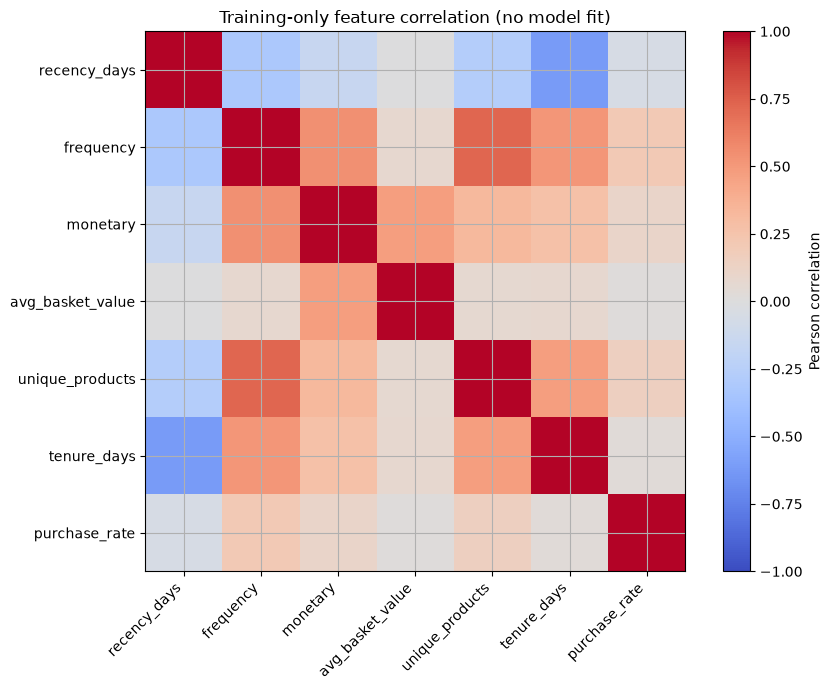

Strongest absolute pairwise correlations:


frequency     unique_products     0.726381
recency_days  tenure_days        -0.609892
frequency     monetary            0.542623
              tenure_days         0.515084
monetary      avg_basket_value    0.474312
dtype: float64

In [8]:
dataset_path = ROOT / "data" / "processed" / lock["dataset"]["path"]
if not dataset_path.exists():
    print("Optional training-feature correlation unavailable: local dataset is not distributed.")
else:
    assert sha256(dataset_path) == lock["dataset"]["sha256"], "Local dataset differs from experiment"
    dataset = pd.read_csv(dataset_path)
    training, reserved = train_test_split(
        dataset, test_size=lock["split"]["test_size"],
        random_state=lock["split"]["random_state"],
        stratify=(dataset["future_revenue"] > 0).astype(int),
    )
    for label, rows in (("train", training), ("test", reserved)):
        digest = hashlib.sha256(rows["Customer ID"].to_numpy().tobytes()).hexdigest()
        assert digest == lock["split"][f"{label}_customer_ids_sha256"]
    correlation = training[lock["numeric_features"]].corr()
    display(correlation)
    fig, ax = plt.subplots(figsize=(9, 7))
    image = ax.imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(correlation)), correlation.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(correlation)), correlation.index)
    ax.set_title("Training-only feature correlation (no model fit)")
    fig.colorbar(image, ax=ax, label="Pearson correlation")
    fig.tight_layout()
    plt.show()
    pairs = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool)).stack()
    print("Strongest absolute pairwise correlations:")
    display(pairs.loc[pairs.abs().sort_values(ascending=False).index].head(5))
    del reserved

## 9. Why OLS is the control/reference model

OLS uses the same customer split, features, target, preprocessing, CV folds,
and scoring as the penalized models. It removes just the regularization
penalty. Therefore the saved comparison asks what adding L2, L1, or a mixture
changed, rather than confounding a penalty with new features or a new split.

OLS establishes the development baseline of 1.728911 CV log RMSE.
Notebook 07 measures how much regularization changed that reference and
why more penalty is not automatically better.

**Checkpoint:** explain why scaling inside a Pipeline is necessary before
comparing penalties, and why the modest OLS R2 is not a revenue guarantee.

In [9]:
for filename, original in initial_hashes.items():
    assert sha256(Path(filename)) == original, f"Artifact changed: {filename}"
current_files = {
    str(path) for directory in (EXPERIMENT, ROOT / "models")
    for path in directory.rglob("*") if path.is_file()
}
assert current_files == set(initial_hashes), "Protected artifact inventory changed."
assert Pipeline.fit is forbid_fit and GridSearchCV.fit is forbid_fit
print("PASS: no fitting/tuning; experiment and model artifact bytes/inventory unchanged.")

PASS: no fitting/tuning; experiment and model artifact bytes/inventory unchanged.
